<a href="https://colab.research.google.com/github/amaldevk/automated-ticket-routing-sla-predictor/blob/main/Ticket_Routing_SLA_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, precision_recall_curve, roc_auc_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras import layers, models
from xgboost import XGBClassifier
import joblib

sns.set_theme(style='whitegrid')

In [29]:
df = pd.read_csv('/content/drive/MyDrive/ENTRI_ASSIGNMENTS/datasets/complaints-2026-10-05_16_49.csv')
print(f'Total Records Loaded: {df.shape[0]}')
print(f'Total Features: {df.shape[1]}')

Total Records Loaded: 52702
Total Features: 15


In [30]:
target_products = [
    'Vehicle loan or lease',
    'Payday loan, title loan, personal loan, or advance loan',
    'Prepaid card',
    'Debt or credit management',
]
df_filtered = df[df['Product'].isin(target_products)].copy()

In [31]:
# Stratified downsampling to 25,000 records
target_n = 25000
counts = df_filtered['Product'].value_counts()
sample_sizes = (counts / len(df_filtered) * target_n).round().astype(int)
diff = target_n - sample_sizes.sum()
if diff != 0:
  sample_sizes.iloc[0] += diff

df_sampled = pd.concat([
    df_filtered[df_filtered['Product'] == prod].sample(n=size, random_state=42)
    for prod, size in sample_sizes.items()
])
print(f'Downsampled Dataset Shape: {df_sampled.shape}')

Downsampled Dataset Shape: (25000, 15)


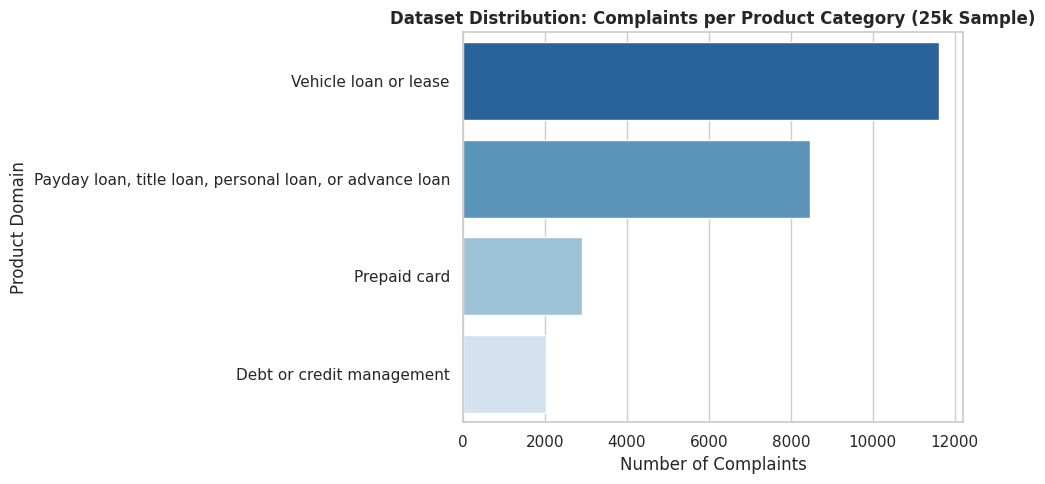

In [32]:
# Generate & Save EDA Visualizations
plt.figure(figsize=(10, 5))
sns.countplot(
    data=df_sampled,
    y='Product',
    order=df_sampled['Product'].value_counts().index,
    palette='Blues_r',
    hue='Product',
    legend=False
)
plt.title('Dataset Distribution: Complaints per Product Category (25k Sample)', fontsize=12, fontweight='bold')
plt.xlabel('Number of Complaints')
plt.ylabel('Product Domain')
plt.tight_layout()
plt.savefig('eda_product_distribution.png')
plt.show()

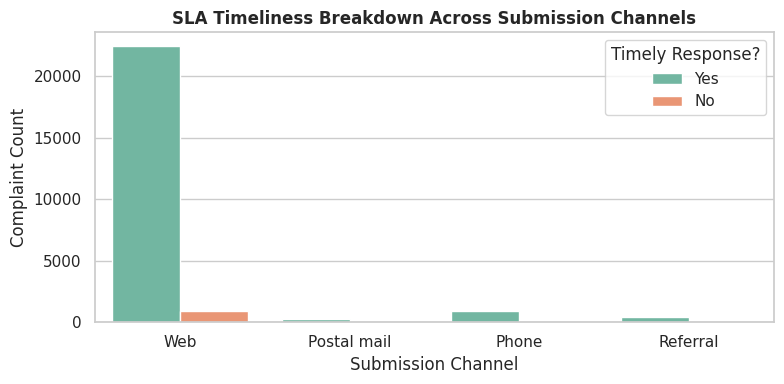

In [33]:
plt.figure(figsize=(8, 4))
sns.countplot(
    data=df_sampled,
    x='Submitted via',
    hue='Timely response?',
    palette='Set2',
)
plt.title('SLA Timeliness Breakdown Across Submission Channels', fontsize=12, fontweight='bold')
plt.xlabel('Submission Channel')
plt.ylabel('Complaint Count')
plt.legend(title='Timely Response?')
plt.tight_layout()
plt.savefig('eda_sla_by_channel.png')
plt.show()

In [34]:
# Data Cleaning & Feature Engineering
print(df_sampled[['Sub-issue', 'Company', 'Submitted via', 'Timely response?']].isnull().sum())


Sub-issue           9961
Company                0
Submitted via          0
Timely response?       0
dtype: int64


In [35]:
text_cols = ['Sub-issue', 'Company', 'Submitted via']
for col in text_cols:
  df_sampled[col] = df_sampled[col].astype(str).str.strip()

df_sampled['combined_text'] = (
    'Sub-issue: ' + df_sampled['Sub-issue'] +
    ' | Company: ' + df_sampled['Company'] +
    ' | Submitted via: ' + df_sampled['Submitted via']
)

In [36]:
df_sampled['sla_breach'] = df_sampled['Timely response?'].apply(lambda x: 1 if x == 'No' else 0)

X = df_sampled['combined_text']
y_routing = df_sampled['Product']
y_sla = df_sampled['sla_breach']

In [37]:
# Stratified Split (80% Train, 10% Validation, 10% Test)
X_train, X_temp, y_rout_train, y_rout_temp, y_sla_train, y_sla_temp = train_test_split(
    X, y_routing, y_sla, test_size=0.20, random_state=42, stratify=y_routing
)
X_val, X_test, y_rout_val, y_rout_test, y_sla_val, y_sla_test = train_test_split(
    X_temp, y_rout_temp, y_sla_temp, test_size=0.50, random_state=42, stratify=y_rout_temp
)

In [38]:
# TF-IDF Vectorization
tfidf = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_vec = tfidf.fit_transform(X_train)
X_val_vec = tfidf.transform(X_val)
X_test_vec = tfidf.transform(X_test)

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_rout_train)
y_val_encoded = label_encoder.transform(y_rout_val)

In [39]:
# Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train_vec, y_train_encoded)
rf_acc = accuracy_score(y_val_encoded, rf_model.predict(X_val_vec))

In [40]:
# XGBoost Classifier
xgb_model = XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=6, random_state=42, n_jobs=-1, eval_metric='mlogloss')
xgb_model.fit(X_train_vec, y_train_encoded)
xgb_acc = accuracy_score(y_val_encoded, xgb_model.predict(X_val_vec))

In [41]:
# TensorFlow Deep Learning MLP Classifier
X_train_dense = X_train_vec.toarray()
X_val_dense = X_val_vec.toarray()

nn_model = models.Sequential([
    layers.Input(shape=(X_train_dense.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(len(label_encoder.classes_), activation='softmax'),
])
nn_model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
nn_model.fit(X_train_dense, y_train_encoded, validation_data=(X_val_dense, y_val_encoded), epochs=10, batch_size=64, verbose=0)
_, nn_acc = nn_model.evaluate(X_val_dense, y_val_encoded, verbose=0)

In [42]:
comparison_df = pd.DataFrame({
    "Model Architecture": ["Random Forest", "XGBoost", "TensorFlow MLP"],
    "Validation Accuracy": [f"{rf_acc:.4f}", f"{xgb_acc:.4f}", f"{nn_acc:.4f}"],
    "Paradigm": ["Tree Ensemble", "Gradient Boosting", "Deep Neural Network"]
})
print(comparison_df.to_string(index=False))


Model Architecture Validation Accuracy            Paradigm
     Random Forest              0.9476       Tree Ensemble
           XGBoost              0.9376   Gradient Boosting
    TensorFlow MLP              0.9516 Deep Neural Network


In [43]:
#  Class Imbalance Correction
neg_count = (y_sla_train == 0).sum()
pos_count = (y_sla_train == 1).sum()
scale_weight = neg_count / pos_count

sla_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    scale_pos_weight=scale_weight,
    random_state=42,
    n_jobs=-1
)
sla_model.fit(X_train_vec, y_sla_train)

val_probs = sla_model.predict_proba(X_val_vec)[:, 1]
precision, recall, thresholds = precision_recall_curve(y_sla_val, val_probs)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
optimal_threshold = thresholds[np.argmax(f1_scores)]

print(f'SLA Risk Model ROC-AUC: {roc_auc_score(y_sla_val, val_probs):.4f}')
print(f'Empirically Derived Optimal SLA Threshold: {optimal_threshold:.4f}\n')

SLA Risk Model ROC-AUC: 0.8922
Empirically Derived Optimal SLA Threshold: 0.8256



In [44]:
import shap
!pip install shap -q

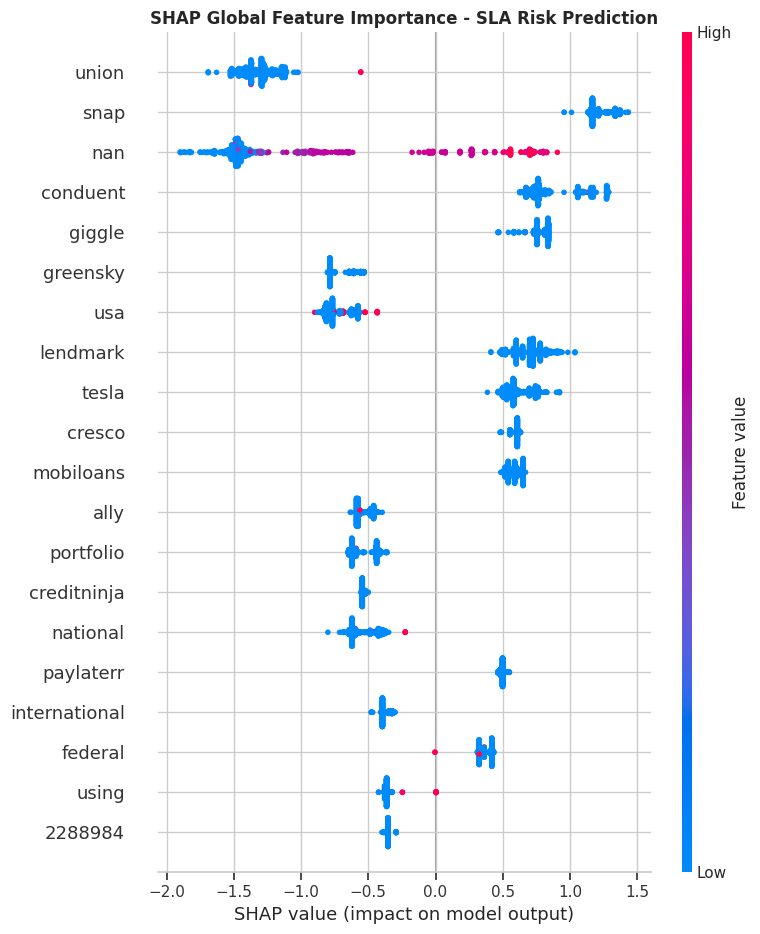

In [45]:
explainer = shap.TreeExplainer(sla_model, feature_names=tfidf.get_feature_names_out())
X_val_sample_dense = X_val_vec[:500].toarray()
shap_values = explainer(X_val_sample_dense)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_val_sample_dense, feature_names=tfidf.get_feature_names_out(), show=False)
plt.title('SHAP Global Feature Importance - SLA Risk Prediction', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('shap_global_summary.png', bbox_inches='tight')
plt.show()

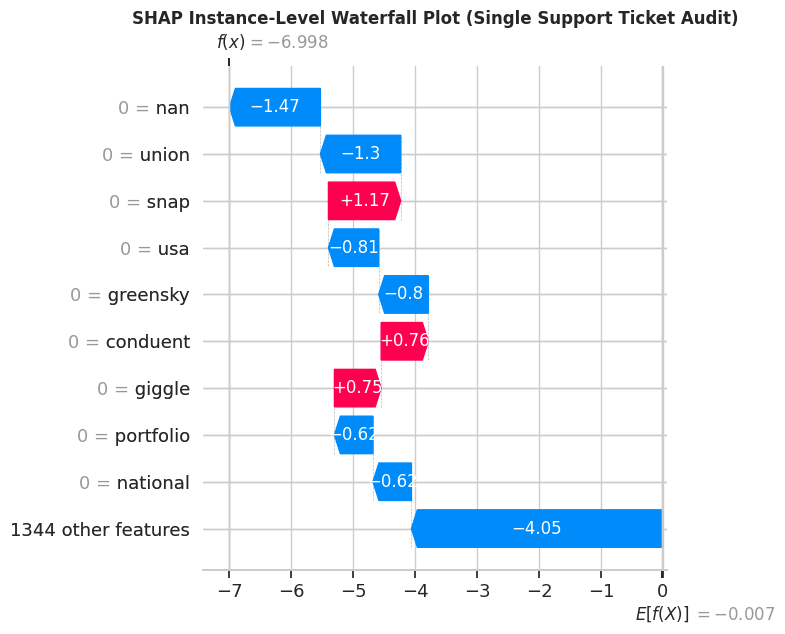

In [46]:
plt.figure(figsize=(10, 6))
shap.plots.waterfall(shap_values[0], show=False)
plt.title(
    'SHAP Instance-Level Waterfall Plot (Single Support Ticket Audit)',
    fontsize=12,
    fontweight='bold',
)
plt.tight_layout()
plt.savefig('shap_waterfall_ticket.png', bbox_inches='tight')
plt.show()

In [47]:
!pip install -q fastapi uvicorn streamlit requests

In [48]:
joblib.dump(tfidf, "tfidf.pkl")
joblib.dump(xgb_model, "xgb_routing_model.pkl")
joblib.dump(rf_model, "rf_routing_model.pkl")
nn_model.save("tensorflow_routing_model.keras")
joblib.dump(sla_model, "sla_model.pkl")
joblib.dump(optimal_threshold, "optimal_threshold.pkl")

['optimal_threshold.pkl']

In [49]:
# Create FastAPI Backend

%%writefile main.py
from fastapi import FastAPI
import joblib
import pandas as pd
import numpy as np
from tensorflow.keras import models
from pydantic import BaseModel

app = FastAPI(title="Enterprise Ticket Routing & SLA API")

tfidf = joblib.load('tfidf.pkl')
routing_model = models.load_model('tensorflow_routing_model.keras')
sla_model = joblib.load('sla_model.pkl')
OPTIMAL_THRESHOLD = joblib.load('optimal_threshold.pkl')

DEPARTMENT_MAPPING = {
    0: "Debt or credit management",
    1: "Payday loan, title loan, personal loan, or advance loan",
    2: "Prepaid card",
    3: "Vehicle loan or lease"
}

class TicketInput(BaseModel):
    sub_issue: str
    company: str
    submitted_via: str

@app.get("/")
def home():
    return {"message": "FastAPI Triage and TensorFlow SLA Risk Engine is Online"}

@app.post("/predict")
def predict_ticket(ticket: TicketInput):
    sub_issue_text = ticket.sub_issue.strip()
    company_name = ticket.company.strip()
    submission_channel = ticket.submitted_via.strip()

    words = sub_issue_text.split()

    if len(words) < 3:
        return {
            "status": "warning",
            "combined_text": sub_issue_text,
            "predicted_department": "⚠️ Insufficient Details (Please enter a full sentence)",
            "sla_risk_status": "⚪ N/A (Cannot assess risk for short input)",
            "sla_probability": 0.0
        }

    # COMBINE FEATURES (Matching training feature schema precisely)
    combined_payload = (
        f"Sub-issue: {sub_issue_text} | Company: {company_name} | Submitted via: {submission_channel}"
    )

    # Vectorize the combined text payload
    vectorized_text = tfidf.transform([combined_payload]).toarray()

    # Predict Department using TensorFlow Routing Model
    preds = routing_model.predict(vectorized_text)
    predicted_dept_encoded = int(np.argmax(preds[0]))
    predicted_dept_name = DEPARTMENT_MAPPING.get(predicted_dept_encoded, f"Department Category {predicted_dept_encoded}")

    # Predict SLA Risk using the combined text payload
    sla_probs = sla_model.predict_proba(tfidf.transform([combined_payload]))[0]
    timely_prob = float(sla_probs[0])

    # 3-Tier Enterprise SLA Mapping
    if timely_prob >= 0.90:
        sla_status = "🟢 Normal / On Track"
    elif timely_prob >= OPTIMAL_THRESHOLD:
        sla_status = "🟡 Warning / At Risk"
    else:
        sla_status = "🔴 Breached / Critical"

    return {
        "status": "success",
        "combined_text": combined_payload,
        "predicted_department": predicted_dept_name,
        "sla_risk_status": sla_status,
        "sla_probability": timely_prob
    }

Overwriting main.py


In [56]:
# Create Streamlit Frontend

%%writefile app.py
import streamlit as st
import requests

# Page Configuration
st.set_page_config(
    page_title="Enterprise Support Triage Command Center",
    page_icon="🛡️",
    layout="wide"
)

# Custom CSS for polished styling
st.markdown("""
    <style>
    .metric-card {
        background-color: #1e2530;
        padding: 20px;
        border-radius: 10px;
        border: 1px solid #2d3748;
        text-align: center;
    }
    .stButton button {
        width: 100%;
        font-weight: bold;
        background-color: #2563eb;
        color: white;
    }
    </style>
""", unsafe_allow_html=True)

# App Header
st.title("🛡️ Enterprise IT & Financial Support Triage Command Center")
st.markdown("Real-time AI routing, predictive SLA risk analysis, and audit panel.")
st.divider()

col1, col2 = st.columns([1, 1], gap="large")

with col1:
    st.subheader("📥 Simulate Support Ticket Intake")
    with st.container(border=True):
        with st.form("triage_form"):
            sub_issue = st.text_input(
                "Sub-issue Description",
                placeholder="ISSUE DESCRIPTION"
            )
            company = st.text_input(
                "Company Name",
                placeholder="COMPANY NAME"
            )
            submitted_via = st.selectbox(
                "SELECT SUBMISSION CHANNEL",
                ["Web", "Phone", "Referral", "Postal mail"]
            )
            st.markdown("<br>", unsafe_allow_html=True)
            submitted = st.form_submit_button("Run AI Triage & SLA Audit 🚀")

with col2:
    st.subheader("📊 Live Triage & Risk Insights")

    if submitted:
        payload = {"sub_issue": sub_issue, "company": company, "submitted_via": submitted_via}
        try:
            with st.spinner("Analyzing ticket features via FastAPI & TensorFlow..."):
                response = requests.post("http://localhost:8000/predict", json=payload)

            if response.status_code == 200:
                data = response.json()

                # Success notification banner
                st.success("Ticket successfully analyzed by FastAPI backend!")

                with st.container(border=True):
                    if data.get("status") == "warning":
                        st.warning(f"**Predicted Department:** {data['predicted_department']}")
                        st.info(f"**SLA Risk Status:** {data['sla_risk_status']}")
                    else:
                        # Display metrics inside structured columns
                        m1, m2 = st.columns(2)
                        with m1:
                            st.metric(label="📂 Predicted Department", value=data["predicted_department"])
                        with m2:
                            st.metric(label="⏱️ SLA Probability Score", value=f"{data['sla_probability']:.2f}")

                        st.divider()

                        # Dynamic colored alert banner for SLA Risk Status
                        sla_status = data["sla_risk_status"]
                        if "Normal" in sla_status:
                            st.success(f"**SLA Risk Status:** {sla_status}")
                        elif "Warning" in sla_status:
                            st.warning(f"**SLA Risk Status:** {sla_status}")
                        else:
                            st.error(f"**SLA Risk Status:** {sla_status}")

                    st.markdown("---")
                    st.caption("**Processed Feature Payload:**")
                    st.code(data["combined_text"], language="text")
            else:
                st.error("Error communicating with backend API.")
        except Exception as e:
            st.warning(f"Could not reach FastAPI server at port 8000. Error: {e}")
    else:
        with st.container(border=True):
            st.info("👈 Submit a support ticket on the left to initialize real-time AI triage and SLA risk scoring.")

Overwriting app.py


In [57]:
!pkill -f streamlit
!pkill -f uvicorn
!pkill -f ssh

get_ipython().system_raw("uvicorn main:app --host 0.0.0.0 --port 8000 &")
get_ipython().system_raw("streamlit run app.py --server.port=8501 --server.enableCORS=false --server.enableXsrfProtection=false &")

import time
!ssh -o StrictHostKeyChecking=no -R 80:localhost:8501 serveo.net > serveo_url.txt 2>&1 &
time.sleep(4)

with open("serveo_url.txt", "r") as f:
    for line in f:
        if "https://" in line:
            print("🚀 Your New Clean Streamlit URL:", line.strip())

🚀 Your New Clean Streamlit URL: Forwarding HTTP traffic from https://6c7bd2fb1d325144-35-252-93-252.serveousercontent.com
